## 1. Nạp dữ liệu và kiểm tra tổng quan
**Mục đích:** Tải tập dữ liệu thô (raw data) từ NASA POWER vào Dataframe để kiểm tra cấu trúc.
**Lưu ý FAIR:** Giữ nguyên vẹn file gốc `.csv`, chỉ đọc dữ liệu vào bộ nhớ máy tính để đảm bảo khả năng tái lập hoàn toàn từ đầu.

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('raw/POWER_Point_Daily_20050101_20251231_016d07N_108d22E_LST.csv', skiprows=12)

display(df.head())
print("Thông tin dữ liệu:")
df.info()

,YEAR,DOY,T2M_MAX,WS10M_MAX,T2M_MIN,PRECTOTCORR
0,2005,1,18.43,5.79,15.70,1.31
1,2005,2,20.54,3.31,15.96,0.07
2,2005,3,23.61,3.60,17.03,0.02
3,2005,4,23.40,3.40,18.46,0.18
4,2005,5,24.33,5.23,18.64,0.84


Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 7670 entries, 0 to 7669
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   YEAR         7670 non-null   int64  
 1   DOY          7670 non-null   int64  
 2   T2M_MAX      7670 non-null   float64
 3   WS10M_MAX    7670 non-null   float64
 4   T2M_MIN      7670 non-null   float64
 5   PRECTOTCORR  7670 non-null   float64
dtypes: float64(4), int64(2)
memory usage: 359.7 KB


## 2. Tiền xử lý dữ liệu: Làm sạch và xử lý giá trị thiếu
**Thao tác:** Kiểm tra các giá trị NaN (Not a Number) hoặc dữ liệu rác.
**Lập luận xử lý:** Nếu số lượng dòng bị thiếu rất nhỏ (<5%), ta có thể loại bỏ để không làm sai lệch phân phối. Nếu nhiều, ta sẽ điền bằng giá trị nội suy hoặc trung vị.

In [45]:
print("Số lượng giá trị thiếu ban đầu:")
print(df.isna().sum())

print("\nSố lượng dữ liệu lỗi (-999):")
print((df == -999).sum())

df_cleaned = df.replace(-999.0, np.nan)
df_cleaned = df_cleaned.dropna()

print(f"\nSố lượng dòng dữ liệu sau khi làm sạch: {len(df_cleaned)}")

Số lượng giá trị thiếu ban đầu:
YEAR           0
DOY            0
T2M_MAX        0
WS10M_MAX      0
T2M_MIN        0
PRECTOTCORR    0
dtype: int64

Số lượng dữ liệu lỗi (-999):
YEAR           0
DOY            0
T2M_MAX        0
WS10M_MAX      0
T2M_MIN        0
PRECTOTCORR    0
dtype: int64

Số lượng dòng dữ liệu sau khi làm sạch: 7670


## 3. Nhận diện Dữ liệu ngoại lai (Outliers) - Các cơn bão
**Thao tác:** Sử dụng biểu đồ hộp (Boxplot) để phân tích sự phân bố của biến sức gió cực đại (WS10M_MAX).
**Lập luận xử lý:** Trong nghiên cứu khí tượng, các "điểm ngoại lai" (outliers) nằm ngoài râu trên của boxplot thể hiện những ngày có sức gió cao bất thường. Đây chính là lúc xảy ra bão hoặc áp thấp nhiệt đới. Do đó, **không xóa bỏ** các điểm này (vì đây là đối tượng nghiên cứu cốt lõi), mà dùng chúng để phân tích cường độ bão.

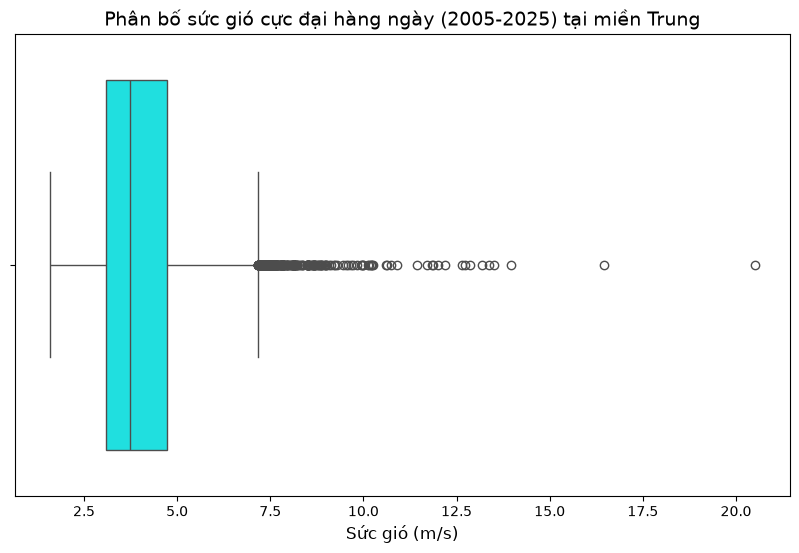


Tổng số ngày có sức gió mạnh bất thường (bão/áp thấp) trong 20 năm: 2 ngày


In [46]:
plt.figure(figsize=(10, 6))

sns.boxplot(x=df_cleaned['WS10M_MAX'], color='cyan') 
plt.title('Phân bố sức gió cực đại hàng ngày (2005-2025) tại miền Trung', fontsize=14)
plt.xlabel('Sức gió (m/s)', fontsize=12)
plt.show()

ngay_bao = df_cleaned[df_cleaned['WS10M_MAX'] > 15]
print(f"\nTổng số ngày có sức gió mạnh bất thường (bão/áp thấp) trong 20 năm: {len(ngay_bao)} ngày")

## 4. Kiểm định giả thuyết: So sánh cường độ bão giữa hai thập kỷ
**Mục tiêu:** Kiểm tra xem sức gió cực đại trong giai đoạn 10 năm sau (2015-2025) có lớn hơn giai đoạn 10 năm đầu (2005-2014) hay không.
**Lập luận chọn kiểm định:** Dựa vào biểu đồ Boxplot, dữ liệu sức gió bị lệch phải (right-skewed) rõ rệt và chứa nhiều điểm ngoại lai, tức là **không tuân theo phân phối chuẩn** (Non-normal distribution). Do đó, không thể sử dụng kiểm định tham số T-test, mà bắt buộc phải chọn **kiểm định phi tham số Mann-Whitney U** để so sánh sự khác biệt giữa hai giai đoạn.

In [47]:
from scipy.stats import mannwhitneyu

giai_doan_1 = df_cleaned[df_cleaned['YEAR'] <= 2014]['WS10M_MAX']
giai_doan_2 = df_cleaned[df_cleaned['YEAR'] > 2014]['WS10M_MAX']

print(f"Số ngày GĐ 1 (2005-2014): {len(giai_doan_1)} | Gió cực đại trung vị: {giai_doan_1.median():.2f} m/s")
print(f"Số ngày GĐ 2 (2015-2025): {len(giai_doan_2)} | Gió cực đại trung vị: {giai_doan_2.median():.2f} m/s")

stat, p_value = mannwhitneyu(giai_doan_2, giai_doan_1, alternative='greater')

print("-" * 50)
print(f"Thống kê U: {stat}")
print(f"Giá trị p-value: {p_value}")
if p_value < 0.05:
    print("=> Kết luận: Có bằng chứng thống kê (p < 0.05) cho thấy sức gió cực đại trong thập kỷ gần đây MẠNH HƠN so với thập kỷ trước.")
else:
    print("=> Kết luận: Không có đủ bằng chứng thống kê (p >= 0.05) để khẳng định sức gió mạnh lên.")

Số ngày GĐ 1 (2005-2014): 3652 | Gió cực đại trung vị: 3.88 m/s
Số ngày GĐ 2 (2015-2025): 4018 | Gió cực đại trung vị: 3.63 m/s
--------------------------------------------------
Thống kê U: 6665139.5
Giá trị p-value: 0.999999999997979
=> Kết luận: Không có đủ bằng chứng thống kê (p >= 0.05) để khẳng định sức gió mạnh lên.


Bảng thống kê mô tả (Descriptive Statistics) toàn bộ 20 năm:


,WS10M_MAX,PRECTOTCORR,T2M_MAX,T2M_MIN
count,7670.000000,7670.000000,7670.000000,7670.000000
mean,4.071005,7.084493,28.702005,23.160879
std,1.391643,19.401718,3.646074,2.846009
min,1.590000,0.000000,15.480000,13.130000
25%,3.090000,0.130000,26.110000,21.000000
50%,3.740000,1.090000,29.030000,23.915000
75%,4.720000,5.370000,31.560000,25.580000
max,20.500000,386.080000,38.680000,27.850000


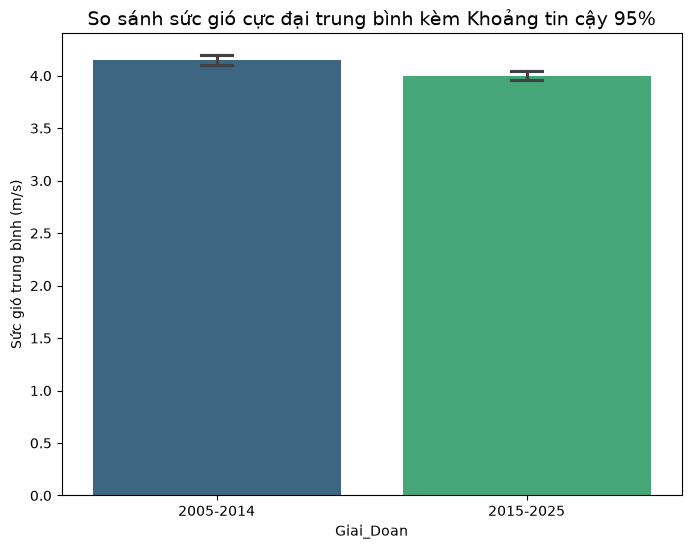

In [48]:
print("Bảng thống kê mô tả (Descriptive Statistics) toàn bộ 20 năm:")
bang_thong_ke = df_cleaned[['WS10M_MAX', 'PRECTOTCORR', 'T2M_MAX', 'T2M_MIN']].describe()
display(bang_thong_ke)

plt.figure(figsize=(8, 6))
df_cleaned['Giai_Doan'] = np.where(df_cleaned['YEAR'] <= 2014, '2005-2014', '2015-2025')
sns.barplot(x='Giai_Doan', y='WS10M_MAX', data=df_cleaned, errorbar=('ci', 95), capsize=0.1, palette='viridis', hue='Giai_Doan', legend=False)
plt.title('So sánh sức gió cực đại trung bình kèm Khoảng tin cậy 95%', fontsize=14)
plt.ylabel('Sức gió trung bình (m/s)')
plt.show()

In [49]:
n1 = len(giai_doan_1)
n2 = len(giai_doan_2)

effect_size = 1 - (2 * stat) / (n1 * n2)

print(f"Giá trị thống kê U: {stat}")
print(f"Độ lớn hiệu ứng (r): {effect_size:.4f}")

if abs(effect_size) < 0.1:
    print("=> Kết luận Effect Size: Sự khác biệt về sức gió giữa 2 thập kỷ là RẤT NHỎ (Không đáng kể về mặt thực tiễn).")

Giá trị thống kê U: 6665139.5
Độ lớn hiệu ứng (r): 0.0916
=> Kết luận Effect Size: Sự khác biệt về sức gió giữa 2 thập kỷ là RẤT NHỎ (Không đáng kể về mặt thực tiễn).


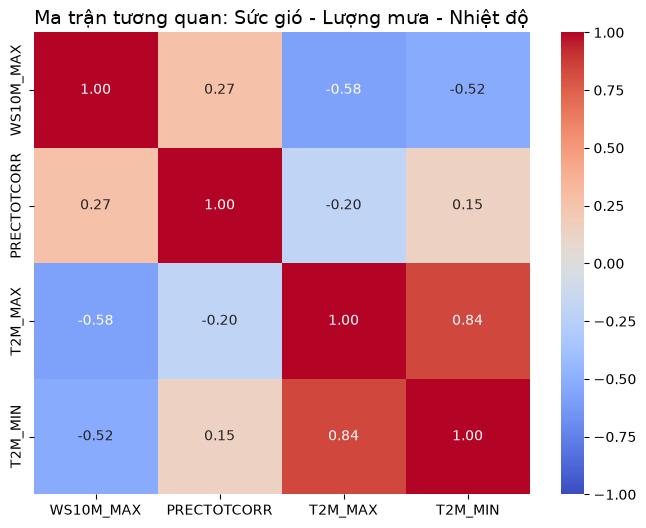

In [50]:
cac_bien_so = ['WS10M_MAX', 'PRECTOTCORR', 'T2M_MAX', 'T2M_MIN']
ma_tran_tuong_quan = df_cleaned[cac_bien_so].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(ma_tran_tuong_quan, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Ma trận tương quan: Sức gió - Lượng mưa - Nhiệt độ', fontsize=14)

plt.savefig('BieuDo_Heatmap.png', dpi=300, bbox_inches='tight') 
plt.show()